In [1]:
print("hello world")


hello world


1. Loading Dataset and Tokenizer...

2. Analyzing Column Artifacts...
Total Rows: 20022
Rows with Code Signal: 16841
Rows lacking Code Signal: 3181 (15.89%)

3. Completion (Output) Length Analysis...
Output Token Length Percentiles:
count    20022.000000
mean        54.058536
std         55.817685
min          0.000000
50%         38.000000
90%        114.000000
95%        153.000000
99%        265.000000
max       1123.000000
Name: output_token_len, dtype: float64

4. Calculating Total Sequence Length (Context Window Usage)...

Full Sequence Percentiles (Prompt + Output):
       total_tokens
count  20022.000000
mean     135.297023
std       58.604168
min       64.000000
50%      121.000000
90%      199.000000
95%      240.000000
99%      349.790000
max     1192.000000

5. Visualizing distributions...


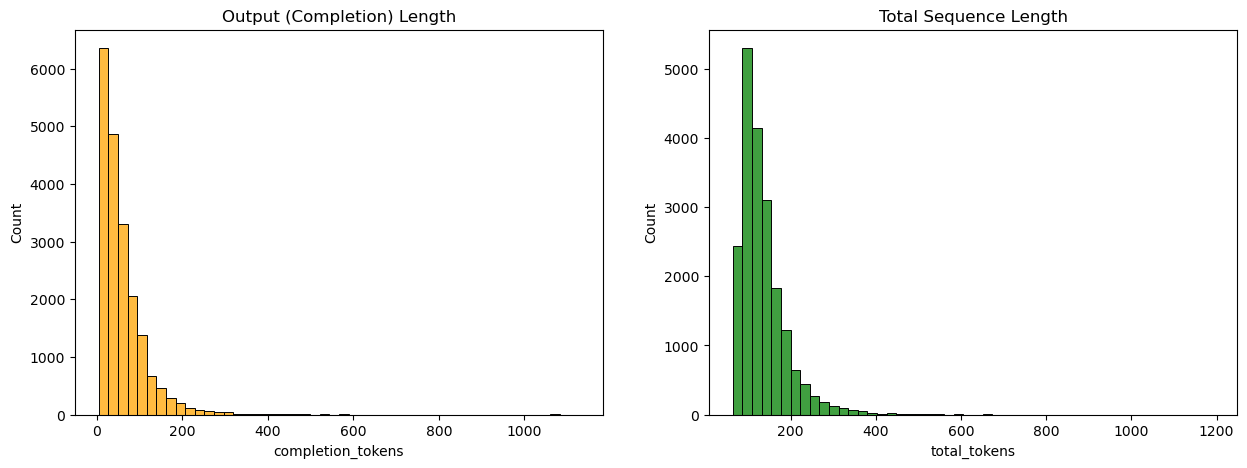

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datasets import load_dataset
from transformers import AutoTokenizer
from sklearn.feature_extraction.text import CountVectorizer


def run_gsm8k_eda(model_id: str = "meta-llama/Meta-Llama-3.1-8B-Instruct"):
    print("1. Loading Dataset and Tokenizer...")
    dataset = load_dataset("openai/gsm8k", "main")
    train_df = dataset["train"].to_pandas()

    # Load the Llama 3 tokenizer to get accurate subword counts
    tokenizer = AutoTokenizer.from_pretrained(model_id)

    print("\n2. Analyzing Structural Integrity...")
    # Verify the #### delimiter exists in every answer
    missing_delimiter = train_df[~train_df["answer"].str.contains("####")]
    print(f"Rows missing '####' delimiter: {len(missing_delimiter)}")

    # Count frequency of <<equation=answer>> annotations
    train_df["calc_annotations_count"] = train_df["answer"].str.count(r"<<.*?>>")
    print(
        f"Average calculator annotations per answer: {train_df['calc_annotations_count'].mean():.2f}"
    )

    print("\n3. Calculating Token Length Distributions...")

    # Apply Llama 3 Chat Template to calculate true sequence lengths
    def calculate_lengths(row):
        messages = [
            {
                "role": "system",
                "content": "You are a mathematical reasoning assistant. Solve the problem step-by-step and provide the final answer after ####.",
            },
            {"role": "user", "content": row["question"]},
            {"role": "assistant", "content": row["answer"]},
        ]
        # Format string without tokenizing to see raw text
        formatted_string = tokenizer.apply_chat_template(messages, tokenize=False)

        prompt_only = messages[:2]
        formatted_prompt = tokenizer.apply_chat_template(prompt_only, tokenize=False)

        # Tokenize to get lengths
        total_tokens = len(tokenizer.encode(formatted_string))
        prompt_tokens = len(tokenizer.encode(formatted_prompt))
        completion_tokens = total_tokens - prompt_tokens

        return pd.Series([prompt_tokens, completion_tokens, total_tokens])

    train_df[["prompt_tokens", "completion_tokens", "total_tokens"]] = train_df.apply(
        calculate_lengths, axis=1
    )

    # Output percentiles to dictate max_length parameter
    print("\nToken Length Percentiles:")
    print(
        train_df[["prompt_tokens", "completion_tokens", "total_tokens"]].describe(
            percentiles=[0.50, 0.90, 0.95, 0.99]
        )
    )

    print("\n4. Plotting Distributions...")
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    sns.histplot(
        train_df["prompt_tokens"], bins=50, ax=axes[0], color="blue"
    ).set_title("Prompt Token Length")
    sns.histplot(
        train_df["completion_tokens"], bins=50, ax=axes[1], color="orange"
    ).set_title("Completion Token Length")
    sns.histplot(
        train_df["total_tokens"], bins=50, ax=axes[2], color="green"
    ).set_title("Total Sequence Length")
    plt.tight_layout()
    plt.show()

    print("\n5. Vocabulary Frequency Analysis (Router Prep)...")
    # Extract top 20 words (excluding English stop words) to verify mathematical signal
    vectorizer = CountVectorizer(stop_words="english", max_features=20)
    word_counts = vectorizer.fit_transform(train_df["question"]).sum(axis=0)
    words_freq = [
        (word, word_counts[0, idx]) for word, idx in vectorizer.vocabulary_.items()
    ]
    words_freq = sorted(words_freq, key=lambda x: x[1], reverse=True)

    words, counts = zip(*words_freq)
    plt.figure(figsize=(10, 6))
    sns.barplot(x=list(counts), y=list(words), palette="viridis")
    plt.title("Top 20 Informative Words in GSM8K Questions")
    plt.show()


def run_codealpaca_eda(model_id: str = "meta-llama/Meta-Llama-3.1-8B-Instruct"):
    print("1. Loading Dataset and Tokenizer...")
    dataset = load_dataset("sahil2801/CodeAlpaca-20k", split="train")
    train_df = dataset.to_pandas()

    tokenizer = AutoTokenizer.from_pretrained(model_id)

    print("\n2. Analyzing Column Artifacts...")
    # Analyzing the Output column for actual coding content
    # Expanded keywords to include HTML, SQL, C++, and structural markers
    code_signals = [
        "def ",
        "import ",
        "class ",
        "return ",
        "print(",
        "{",
        "const ",
        "var ",
        "<html>",
        "SELECT ",
        "FROM ",
        "#include",
        "public ",
        "static ",
        "void ",
        "if ",
        "for ",
        "while ",
        "let ",
        "arr =",
        "lst =",
        " = ",
    ]

    train_df["has_code_signal"] = train_df["output"].apply(
        lambda x: any(kw in str(x) for kw in code_signals)
    )

    low_signal_df = train_df[train_df["has_code_signal"] == False]
    print(f"Total Rows: {len(train_df)}")
    print(f"Rows with Code Signal: {len(train_df) - len(low_signal_df)}")
    print(
        f"Rows lacking Code Signal: {len(low_signal_df)} ({(len(low_signal_df) / len(train_df)) * 100:.2f}%)"
    )

    print("\n3. Completion (Output) Length Analysis...")

    # This specifically measures the 'assistant' portion of the training data
    def get_completion_length(text):
        tokens = tokenizer.encode(str(text), add_special_tokens=False)
        return len(tokens)

    # We sample a portion if calculation is too slow, but for 20k it should be fine
    train_df["output_token_len"] = train_df["output"].apply(get_completion_length)

    print("Output Token Length Percentiles:")
    print(train_df["output_token_len"].describe(percentiles=[0.5, 0.9, 0.95, 0.99]))

    print("\n4. Calculating Total Sequence Length (Context Window Usage)...")

    def calculate_total_lengths(row):
        user_content = str(row.get("instruction", "")).strip()
        raw_input = str(row.get("input", "")).strip()

        if raw_input and raw_input.lower() != "< noinput >":
            user_content += f"\n\nContext/Input:\n{raw_input}"

        messages = [
            {
                "role": "system",
                "content": "You are an expert programming assistant. Write clean, efficient, and well-documented code.",
            },
            {"role": "user", "content": user_content},
            {"role": "assistant", "content": str(row.get("output", "")).strip()},
        ]

        formatted_string = tokenizer.apply_chat_template(messages, tokenize=False)
        total_tokens = len(tokenizer.encode(formatted_string))

        # We also want to see how much of the sequence is prompt vs output
        prompt_only = messages[:2]
        formatted_prompt = tokenizer.apply_chat_template(prompt_only, tokenize=False)
        prompt_tokens = len(tokenizer.encode(formatted_prompt))

        return pd.Series([prompt_tokens, (total_tokens - prompt_tokens), total_tokens])

    train_df[["prompt_tokens", "completion_tokens", "total_tokens"]] = train_df.apply(
        calculate_total_lengths, axis=1
    )

    print("\nFull Sequence Percentiles (Prompt + Output):")
    print(train_df[["total_tokens"]].describe(percentiles=[0.50, 0.90, 0.95, 0.99]))

    print("\n5. Visualizing distributions...")
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))
    sns.histplot(
        train_df["completion_tokens"], bins=50, ax=axes[0], color="orange"
    ).set_title("Output (Completion) Length")
    sns.histplot(
        train_df["total_tokens"], bins=50, ax=axes[1], color="green"
    ).set_title("Total Sequence Length")
    plt.show()


if __name__ == "__main__":
    # run_gsm8k_eda()
    run_codealpaca_eda()
